In [1]:
import matplotlib.pyplot as plt
import numpy as np

T = 1000  # K
def equilibrium_constant(T):
    K_eq = np.exp(-13.148 + 1.077 * np.log(T) + 5.44e-4 * T - 1.125e-7 * T**2 + 5693.5 / T - 49170 / T**2)
    return K_eq
# Calculate equilibrium constant values
K_eq = equilibrium_constant(T)

def equilibrium_compositions(K_eq):
    molefr_CO = 1 / (2 * (1 + np.sqrt(K_eq)))
    molefr_CO2 = np.sqrt(K_eq) / (2 * (1 + np.sqrt(K_eq)))
    molefr_H2 = np.sqrt(K_eq) / (2 * (1 + np.sqrt(K_eq))) 
    return molefr_CO, molefr_CO2, molefr_H2

molefr_CO, molefr_CO2, molefr_H2 = equilibrium_compositions(K_eq)

# Constants
k_o_sq = 0.113
dEA = -47554  # J/mol
T_ref = 500 
a = 1.027 
b = -0.303 
c = 0.038 
R = 8.314  # J/(mol·K)
P = 5e-1  # MPa (5e5 Pa)

# Temperature range for x-axis
T_FT = 473

P_CO0 = molefr_CO * P
P_CO20 = molefr_CO2 * P
P_H20 = molefr_H2 * P
    
C_CO0 = P_CO0 / (R * T_FT)
C_CO20 = P_CO20 / (R * T_FT)
C_H20 = P_H20 / (R * T_FT)
    
α = (1 + (C_H20**c / (k_o_sq * np.exp((dEA / R) * ((1 / T_ref) - (1 / T_FT))) * (C_CO0**a + C_CO20**b))))**-1
    
print(α)
print("Mole fraction of CO:", molefr_CO)
print("Concentration of CO:", C_CO0)
print("pressure of CO:", P_CO0)
print("pressure of H2:", P_H20)

0.8780718279867816
Mole fraction of CO: 0.22709674763289456
Concentration of CO: 2.88741865440161e-05
pressure of CO: 0.11354837381644728
pressure of H2: 0.13645162618355272


n= 1, w_n=0.01487
n= 2, w_n=0.02611
n= 3, w_n=0.03439
n= 4, w_n=0.04026
n= 5, w_n=0.04419
n= 6, w_n=0.04656
n= 7, w_n=0.04770
n= 8, w_n=0.04786
n= 9, w_n=0.04728
n=10, w_n=0.04613
n=11, w_n=0.04456
n=12, w_n=0.04268
n=13, w_n=0.04060
n=14, w_n=0.03839
n=15, w_n=0.03612
n=16, w_n=0.03383
n=17, w_n=0.03156
n=18, w_n=0.02934
n=19, w_n=0.02720
n=20, w_n=0.02514
n=21, w_n=0.02318
n=22, w_n=0.02132
n=23, w_n=0.01957
n=24, w_n=0.01793
n=25, w_n=0.01640
n=26, w_n=0.01498
n=27, w_n=0.01366
n=28, w_n=0.01244
n=29, w_n=0.01131
n=30, w_n=0.01027
n=31, w_n=0.00932
n=32, w_n=0.00845
n=33, w_n=0.00765
n=34, w_n=0.00692
n=35, w_n=0.00626
n=36, w_n=0.00565
n=37, w_n=0.00510
n=38, w_n=0.00460
n=39, w_n=0.00414
n=40, w_n=0.00373
n=41, w_n=0.00336
n=42, w_n=0.00302
n=43, w_n=0.00272
n=44, w_n=0.00244
n=45, w_n=0.00219
n=46, w_n=0.00197
n=47, w_n=0.00176
n=48, w_n=0.00158
n=49, w_n=0.00142
Sum (1..50): 0.9880742969520258


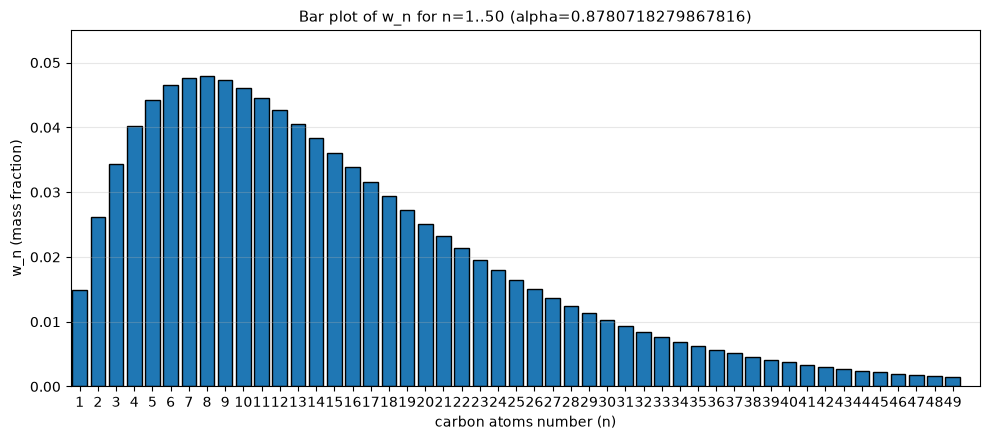

In [2]:
n_values = np.arange(1, 50)
w_values = n_values * α ** (n_values - 1) * (1 - α) ** 2
total = w_values.sum()

# Print values and sum
for n, w in zip(n_values, w_values):
    print(f"n={n:2d}, w_n={w:.5f}")
print("Sum (1..50):", total)

# Plot bar chart
plt.figure(figsize=(10, 4.5))
plt.bar(n_values, w_values, color='tab:blue', edgecolor='black', width=0.8)
plt.xlabel('carbon atoms number (n)', fontsize=10)
plt.ylabel('w_n (mass fraction)', fontsize=10)
plt.title(f'Bar plot of w_n for n=1..{50} (alpha={α})', fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.xlim(0.5, 50 + 0.5)
plt.ylim(0, w_values.max() * 1.15) 
plt.xticks(n_values)        # show every integer tick; remove or thin ticks if too crowded
plt.tight_layout()
plt.show()

In [3]:
import numpy as np

# --- choose mode: demo_mode -> visible changes, phys_mode -> uses Arrhenius you gave ---
demo_mode = True   # set False to run the Arrhenius rate with your parameters

# --- constants and inputs (adjust as needed) ---
R = 8.314            # J/mol/K
T_FT = 473        # K (reactor temperature)
P_CO0 = 1.0e5        # Pa
P_H20 = 2.0e5        # Pa

# convert inlet pressures -> concentrations (ideal gas)
C_CO0 = P_CO0 / (R * T_FT)
C_H20 = P_H20 / (R * T_FT)

a = -0.75
b = 0.996
N = 100
tau = 35.55        # s

# Arrhenius params you provided
E = 7.64e5          # J/mol
k0 = 5.16e5          # pre-exponential (units must match pressure units used below)

# a multiplier to artificially scale k0 for quick demonstrations (leave 1 for physical)
k0_scale = 1.0 if not demo_mode else 1e30

def r_arrhenius(T, p_CO_pa, p_H2_pa, k0_local=k0):
    # If your k0 expects MPa uncomment conversion; here we assume k0 applies to Pa, so NO conversion.
    # If your k0 is for MPa, do p_CO = p_CO_pa/1e6 and p_H2 = p_H2_pa/1e6 and adjust k0 accordingly.
    p_CO = p_CO_pa
    p_H2 = p_H2_pa
    if p_CO <= 0 or p_H2 <= 0:
        return 0.0
    # compute in log-space
    ln_k0 = np.log(k0_local)
    ln_r = ln_k0 - E / (R * T) + a * np.log(p_CO) + b * np.log(p_H2)
    return np.exp(ln_r)

# A simple demo rate (units: mol/m^3/s) that will show stage-to-stage change:
def r_demo(C_CO, C_H2, k_demo=1e-4):
    # simple power-law in concentrations (safe, visible)
    return k_demo * (C_CO ** 1.0) * (C_H2 ** 0.5)

# --- initialize arrays ---
C_CO = np.zeros(N + 1)
C_H2 = np.zeros(N + 1)
r_list = np.zeros(N + 1)

C_CO[0] = C_CO0
C_H2[0] = C_H20

# --- stage loop ---
for i in range(1, N + 1):
    # compute partial pressures at previous stage using reactor temperature T_FT
    p_CO_prev = C_CO[i-1] * R * T_FT
    p_H2_prev = C_H2[i-1] * R * T_FT

    if demo_mode:
        r_prev = r_demo(C_CO[i-1], C_H2[i-1], k_demo=1e-4)   # adjust k_demo to tune speed
    else:
        r_prev = r_arrhenius(T_FT, p_CO_prev, p_H2_prev, k0_local=k0 * k0_scale)

    # debug prints for first few stages
    if i <= 4:
        print(f"DEBUG stage {i-1}: p_CO={p_CO_prev:.3e} Pa, p_H2={p_H2_prev:.3e} Pa, r_prev={r_prev:.3e}, tau*r={tau*r_prev:.3e}")

    # update concentrations (explicit forward Euler)
    delta_CO = tau * r_prev
    delta_H2 = 2.0 * tau * r_prev    # stoichiometry 2:1

    C_CO[i] = max(C_CO[i-1] - delta_CO, 0.0)
    C_H2[i] = max(C_H2[i-1] - delta_H2, 0.0)

    r_list[i] = r_prev

# --- print summary with enough precision ---
print(f"\nInlet (T={T_FT} K): P_CO0={P_CO0:.2e} Pa, P_H20={P_H20:.2e} Pa")
print(f"Inlet concentrations: C_CO0={C_CO0:.6e} mol/m^3, C_H20={C_H20:.6e} mol/m^3")
print(f"tau = {tau:.2e} s, N = {N}\n")

for i in range(0, N + 1):
    if i == 1 or i % 10 == 0 or i == N:
        pco = C_CO[i] * R * T_FT
        ph2 = C_H2[i] * R * T_FT
        conv = (C_CO0 - C_CO[i]) / C_CO0 if C_CO0 > 0 else 0.0
        print(f"Stage {i:3d}: C_CO={C_CO[i]:.9e}, C_H2={C_H2[i]:.9e}, p_CO={pco:.3e} Pa, p_H2={ph2:.3e} Pa, conv={conv:.9e}")

DEBUG stage 0: p_CO=1.000e+05 Pa, p_H2=2.000e+05 Pa, r_prev=1.813e-02, tau*r=6.447e-01
DEBUG stage 1: p_CO=9.746e+04 Pa, p_H2=1.949e+05 Pa, r_prev=1.745e-02, tau*r=6.203e-01
DEBUG stage 2: p_CO=9.503e+04 Pa, p_H2=1.901e+05 Pa, r_prev=1.680e-02, tau*r=5.972e-01
DEBUG stage 3: p_CO=9.268e+04 Pa, p_H2=1.854e+05 Pa, r_prev=1.618e-02, tau*r=5.752e-01

Inlet (T=473 K): P_CO0=1.00e+05 Pa, P_H20=2.00e+05 Pa
Inlet concentrations: C_CO0=2.542897e+01 mol/m^3, C_H20=5.085795e+01 mol/m^3
tau = 3.55e+01 s, N = 100

Stage   0: C_CO=2.542897408e+01, C_H2=5.085794816e+01, p_CO=1.000e+05 Pa, p_H2=2.000e+05 Pa, conv=0.000000000e+00
Stage   1: C_CO=2.478428864e+01, C_H2=4.956857728e+01, p_CO=9.746e+04 Pa, p_H2=1.949e+05 Pa, conv=2.535239674e-02
Stage  10: C_CO=1.994675400e+01, C_H2=3.989350800e+01, p_CO=7.844e+04 Pa, p_H2=1.569e+05 Pa, conv=2.155895107e-01
Stage  20: C_CO=1.607023916e+01, C_H2=3.214047833e+01, p_CO=6.320e+04 Pa, p_H2=1.264e+05 Pa, conv=3.680343094e-01
Stage  30: C_CO=1.322696984e+01, C_H2

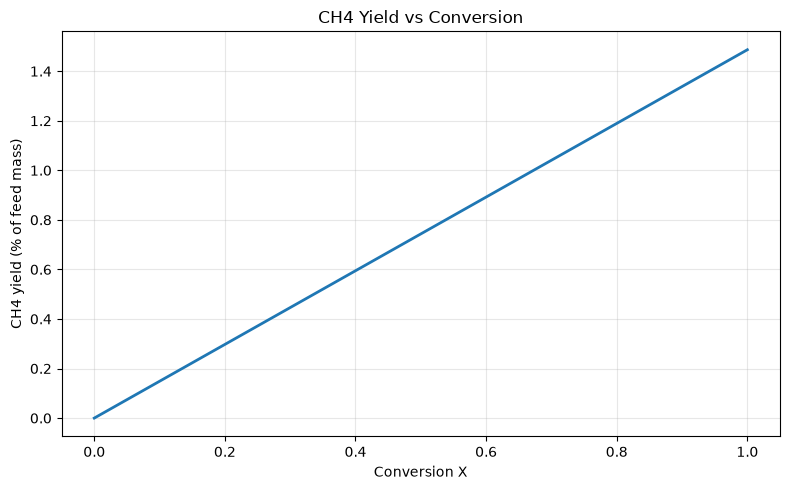

alpha = 0.8780718279867816
w_CH4 = 0.014866
CH4 yield formula = 0.014866 * X
CH4 yield at X=0.8 = 1.189%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = np.linspace(0, 1, 101)  # conversion from 0 to 1

# methane fraction: n=1
w_ch4 = (1 - α) ** 2

# methane yield vs conversion
yield_ch4 = X * w_ch4
yield_ch4_percent = 100 * yield_ch4

plt.figure(figsize=(8, 5))
plt.plot(X, yield_ch4_percent, color='tab:blue', linewidth=2)
plt.xlabel("Conversion X")
plt.ylabel("CH4 yield (% of feed mass)")
plt.title(f"CH4 Yield vs Conversion")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"alpha = {α}")
print(f"w_CH4 = {w_ch4:.6f}")
print(f"CH4 yield formula = {w_ch4:.6f} * X")
print(f"CH4 yield at X=0.8 = {100*w_ch4*0.8:.3f}%")

alpha = 0.83
w_CH4 = 0.028900
conversion    CH4 yield (%)
 0.00            0.000
 0.03            0.073
 0.22            0.623
 0.37            1.064
 0.48            1.387
 0.56            1.631
 0.63            1.820
 0.68            1.969
 0.72            2.089
 0.76            2.187
 0.78            2.268
 0.81            2.336


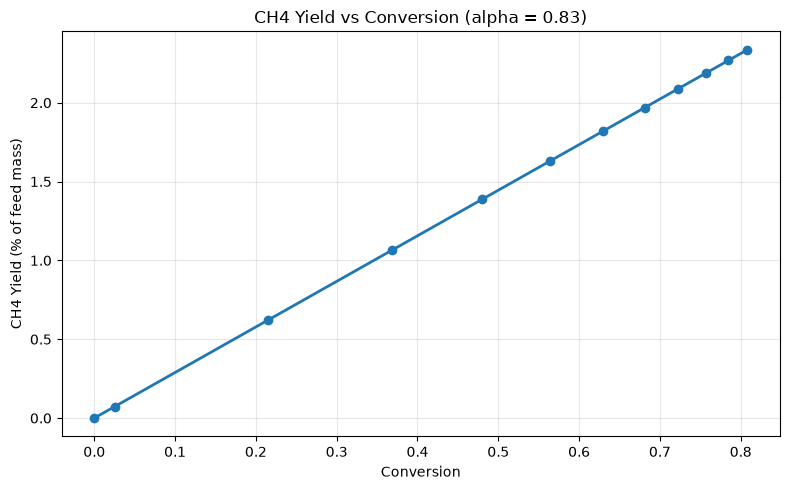

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Your conversion values (replace with your actual data)
conversion = np.array([
    0.000000000e+00, 2.535239674e-02,
    2.155895107e-01, 3.680343094e-01,
    4.798465011e-01, 5.643143205e-01,
    6.296977470e-01, 6.813530923e-01,
    7.228784937e-01, 7.567643785e-01,
    7.847792951e-01, 8.082074570e-01
])

alpha = 0.83

# Methane mass fraction in product distribution
w_ch4 = (1 - alpha) ** 2

# Yield of CH4 as a function of conversion
yield_ch4 = conversion * w_ch4
yield_ch4_percent = 100 * yield_ch4

print(f"alpha = {alpha}")
print(f"w_CH4 = {w_ch4:.6f}")
print("conversion    CH4 yield (%)")
for x, y in zip(conversion, yield_ch4_percent):
    print(f"{x:5.2f}          {y:7.3f}")

plt.figure(figsize=(8, 5))
plt.plot(conversion, yield_ch4_percent, 'o-', color='tab:blue', linewidth=2, markersize=6)
plt.xlabel("Conversion")
plt.ylabel("CH4 Yield (% of feed mass)")
plt.title(f"CH4 Yield vs Conversion (alpha = {alpha})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()